# White Wine Quality Prediction

## Introduction

This project uses the White Wine Quality dataset, which contains 11 physicochemical properties of red wines (such as acidity, sugar, sulfur dioxide and alcohol) and a quality score given by tasters.

**Goal:** Build and compare maching learning model is that predict whether a white wine is of good quality (good wine : quality $ \geq $ 6) based on its psycochemical properties, and evaluate how much they improve over simple baseline (Dummy and Logistic Regression)

**Dataset:** The White Wine Quality dataset from UCI Machine Learning Repository. It contains 4.898 white wine samples with 12 columns: 11 physicochemical features and 1 target (`quality`). After removing 240 duplicate rows, 1359 samples remain.

**Workflow:** inspect the data, cleaning, exploratory data analysis (EDA), modeling and evaluation, feature engineering,and conclusion.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# 1. Data Loading and Cleaning


### 1.1. Inspect Data

In [2]:
df = pd.read_csv('winequality-white.csv', sep=';')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
df.shape

(4898, 12)

In [4]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


In [7]:
d = df.describe().T
d['max vs q3'] = d['max'] / d['75%'].sort_values(ascending=False)
d['max vs q3'].sort_values(ascending=False)

chlorides               6.920000
residual sugar          6.646465
free sulfur dioxide     6.282609
citric acid             4.256410
volatile acidity        3.437500
total sulfur dioxide    2.634731
sulphates               1.963636
fixed acidity           1.945205
quality                 1.500000
alcohol                 1.245614
pH                      1.164634
density                 1.043048
Name: max vs q3, dtype: float64

### Max-to-Q3 (75%) Ratio Findings

- **Outlier (ratio > 3):** columns `chlorides`, `residual sugar`, `free sulfur dioxide`, `citric acid` and `volatile acidity`. Outlier are suspected.
- **Warning (ratio > 1.5 and <= 3:** columns `total sulfur dioxide`, `sulphates`, and 'fixed acidity'. Possible outliers.
- **Normal (ratio < 1.5):** all remaining columns.

In [8]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(937)

### 1.2. Data Cleaning

In [10]:
df = df.drop_duplicates()
df.shape

(3961, 12)

#### Data Cleaning 
- Found 937 duplicate rows in the dataset.
- Duplicates were removed, reducing the data from 4898 to 3961 rows.
- No missing values were found
- Outliers were not removed at this stage; the decision will be made after visualization in the EDA step.

# 2. Exploratory Data Analysis (EDA)

In [11]:
bin_enc = df['quality']

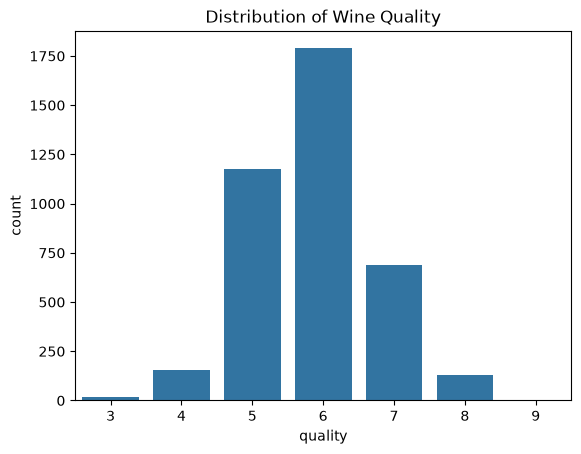

quality
3     0.50
4     3.86
5    29.66
6    45.14
7    17.39
8     3.31
9     0.13
Name: proportion, dtype: float64

In [12]:
#distribution of target
sns.countplot(x='quality', data=df)
plt.title('Distribution of Wine Quality')
plt.show()

df['quality'].value_counts().sort_index()
round(df['quality'].value_counts(normalize=True).sort_index() * 100, 2)

### Target Distribution (quality)

- Quality scores are concentrated at 5 (29.66%) and 6 (45.14%).
- Scores 3 (0.50%) and 9 (0.13%) very few observations.
- The target is imbalanced, so accuracy alone may be misleading during modeling.

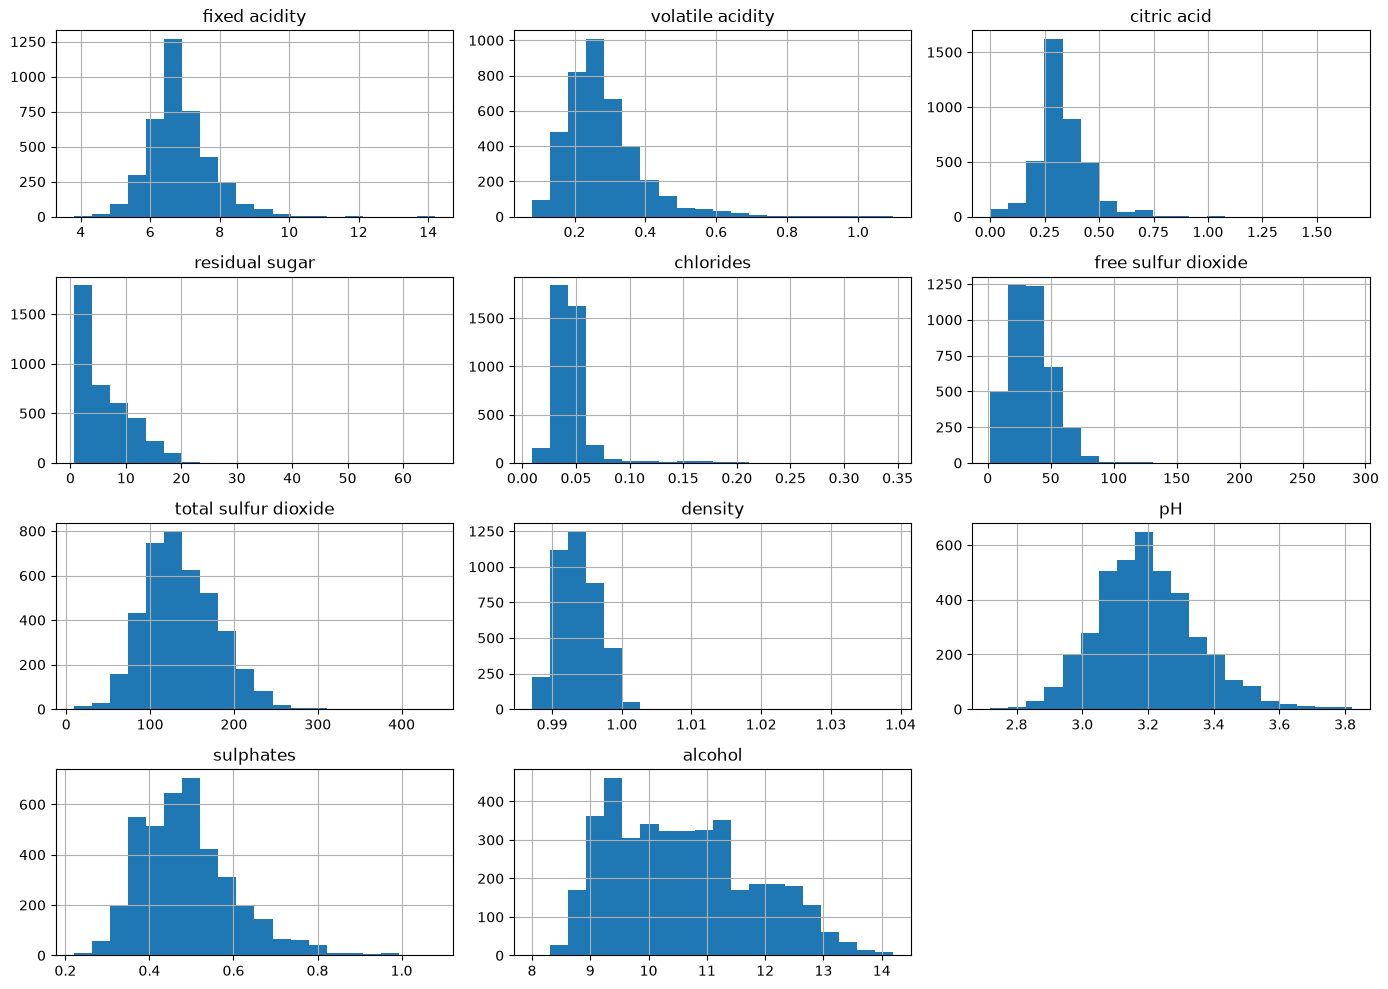

In [13]:
#Distribution of every feature
df.drop('quality', axis=1).hist(figsize=(14,10), bins=20)
plt.tight_layout()
plt.show()

In [14]:
df.drop('quality', axis=1).skew().sort_values()

alcohol                 0.450697
pH                      0.455457
total sulfur dioxide    0.456800
fixed acidity           0.696100
sulphates               0.937853
density                 1.273318
citric acid             1.310601
residual sugar          1.333639
free sulfur dioxide     1.566680
volatile acidity        1.641081
chlorides               4.969076
dtype: float64

### 2.1 Outlier Check

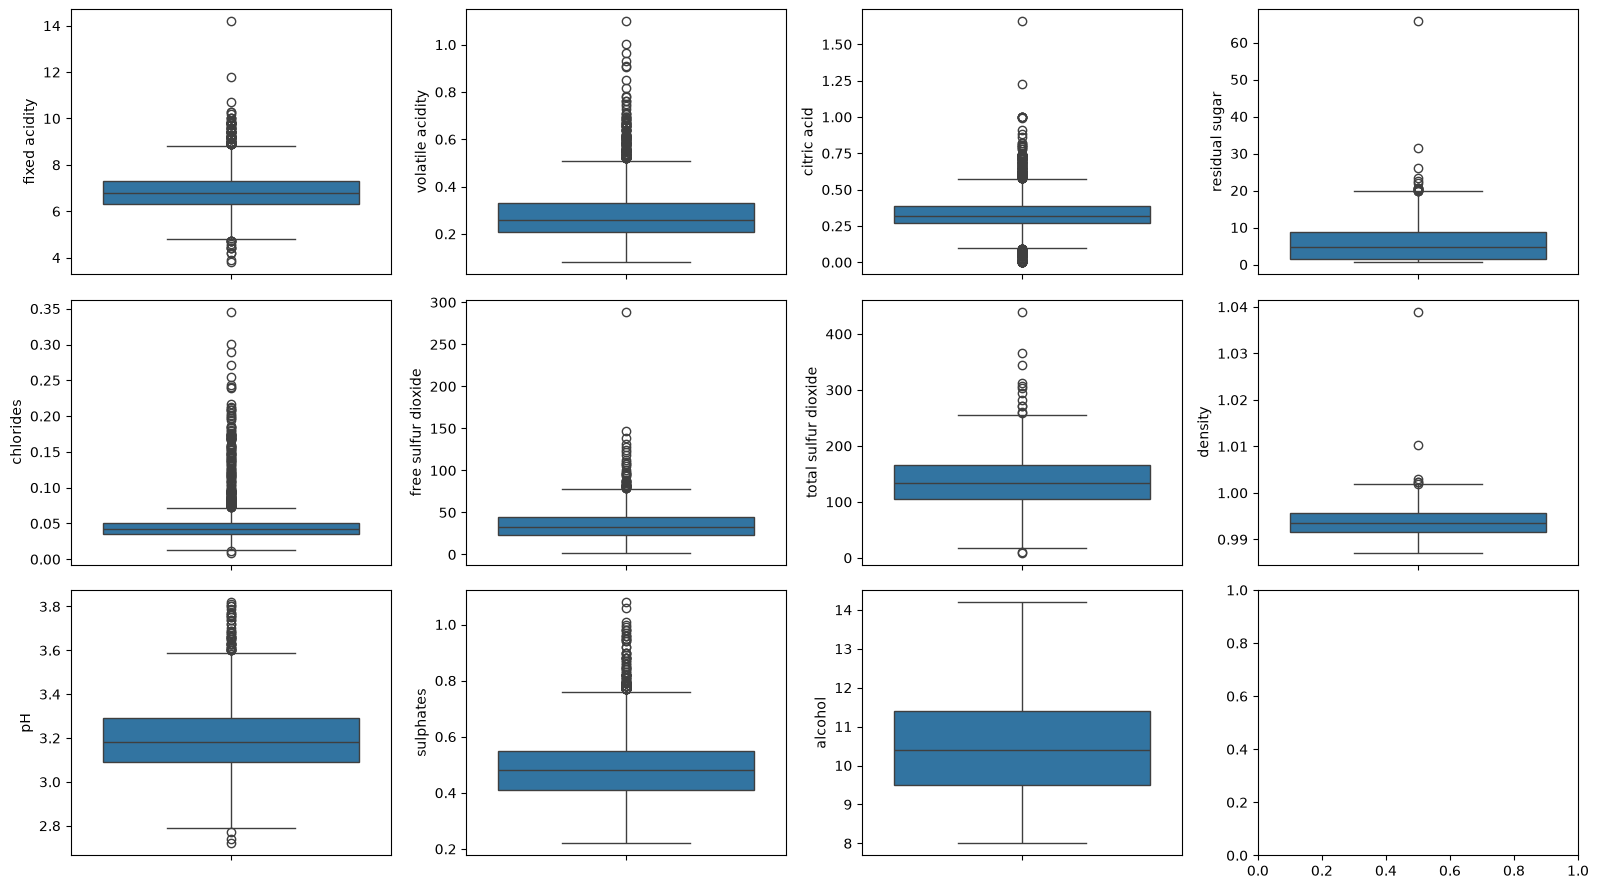

In [15]:
feature = df.drop('quality', axis=1).columns
fig, axes = plt.subplots(3,4, figsize=(16,9))
for ax, c in zip(axes.flat, feature):
    sns.boxplot(y=df[c], ax=ax)

plt.tight_layout()
plt.show()

In [16]:
feature = df.drop('quality', axis=1).columns
result = []
for c in feature:
    q1,q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    result.append([c, n, round(n / len(df) * 100, 2)])

out = pd.DataFrame(result, columns=['Column', 'Number of Outlier', 'Percentage'])
out.sort_values('Number of Outlier', ascending=False)

,Column,Number of Outlier,Percentage
2,citric acid,223,5.63
4,chlorides,178,4.49
1,volatile acidity,133,3.36
0,fixed acidity,106,2.68
9,sulphates,96,2.42
8,pH,46,1.16
5,free sulfur dioxide,44,1.11
3,residual sugar,16,0.40
6,total sulfur dioxide,14,0.35
7,density,6,0.15


### Outlier Analysis

- All features contain outliers except `alcohol` based on the IQR rule.
- Most features are right-skewed, featrues with the highest outlier counts are `citric acid`, consistent with their max/Q3 ratio.
- `density`, `free ulfur dioxide`, `citric acid` and `residual sugar` show high kurtosis, driven by a few extreme values.
- The outliers appear to be natural variation (right-skewed distribution), not data errors.
- Outliers were kept in the dataset.

In [17]:
#checking the ratio (max/q3), percentage, skewness for every features
feature = df.drop('quality', axis=1).columns

result = []
for c in feature:
    q1,q3 = df[c].quantile([0.25, 0.75])
    upper_bound = q3 + 1.5 * (q3 - q1)
    result.append({
        'Column': c,
        'Ratio': (df[c].max() / q3).round(2),
        'Number of Outlier': (df[c] > upper_bound).sum(),
        'Percentage': round((df[c] > upper_bound).mean() * 100, 2),
        'Skewness': round(df[c].skew(),2)
    })
table = pd.DataFrame(result).sort_values('Percentage', ascending=False)
table

,Column,Ratio,Number of Outlier,Percentage,Skewness
4,chlorides,6.92,176,4.44,4.97
2,citric acid,4.26,145,3.66,1.31
1,volatile acidity,3.33,133,3.36,1.64
9,sulphates,1.96,96,2.42,0.94
0,fixed acidity,1.95,92,2.32,0.70
5,free sulfur dioxide,6.42,44,1.11,1.57
8,pH,1.16,43,1.09,0.46
3,residual sugar,7.39,16,0.40,1.33
6,total sulfur dioxide,2.65,12,0.30,0.46
7,density,1.04,6,0.15,1.27


- Detailed analysis focuses on features with a high max/Q3 ratio (`residual sugar`), high outlier percentage (`chlorides`), or strong skewness(chlorides).
- `residual sugar` has the highest max/Q3 ratio, indicating a very few exteme values.
- `chlorides` has the highest percentage of outliers, indicating a longer and more gradual right all.
- both features are right-skewed, so outliers appear to be natural variation (e.g., wine with high salt or sugar content) rather than data errors.
- Outliers were kept in the dataset at this stage.

In [18]:
#make sure chloride and residual 
print(df.skew().sort_values(ascending=False))
print(df.kurt().sort_values(ascending=False))

chlorides               4.969076
volatile acidity        1.641081
free sulfur dioxide     1.566680
residual sugar          1.333639
citric acid             1.310601
density                 1.273318
sulphates               0.937853
fixed acidity           0.696100
total sulfur dioxide    0.456800
pH                      0.455457
alcohol                 0.450697
quality                 0.112004
dtype: float64
chlorides               35.530288
density                 14.184892
free sulfur dioxide     13.434025
citric acid              6.844808
residual sugar           5.681512
volatile acidity         5.327754
fixed acidity            2.253047
sulphates                1.565021
total sulfur dioxide     0.735258
pH                       0.549957
quality                  0.299345
alcohol                 -0.695980
dtype: float64


### 2.2. Correlation Analysis

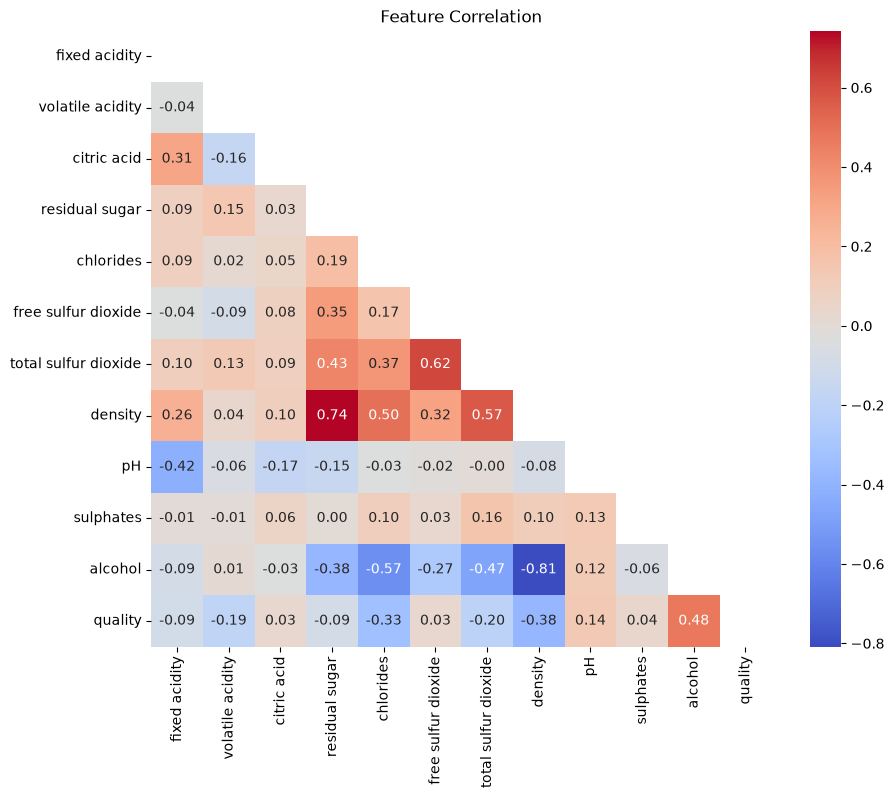

alcohol                 0.48
density                -0.38
chlorides              -0.33
total sulfur dioxide   -0.20
volatile acidity       -0.19
pH                      0.14
fixed acidity          -0.09
residual sugar         -0.09
sulphates               0.04
free sulfur dioxide     0.03
citric acid             0.03
Name: quality, dtype: float64

In [19]:
corr = df.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10,8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation')
plt.show()

corr['quality'].drop('quality').sort_values(key=abs, ascending=False).round(2)

### 2.3. Feature vs Quality

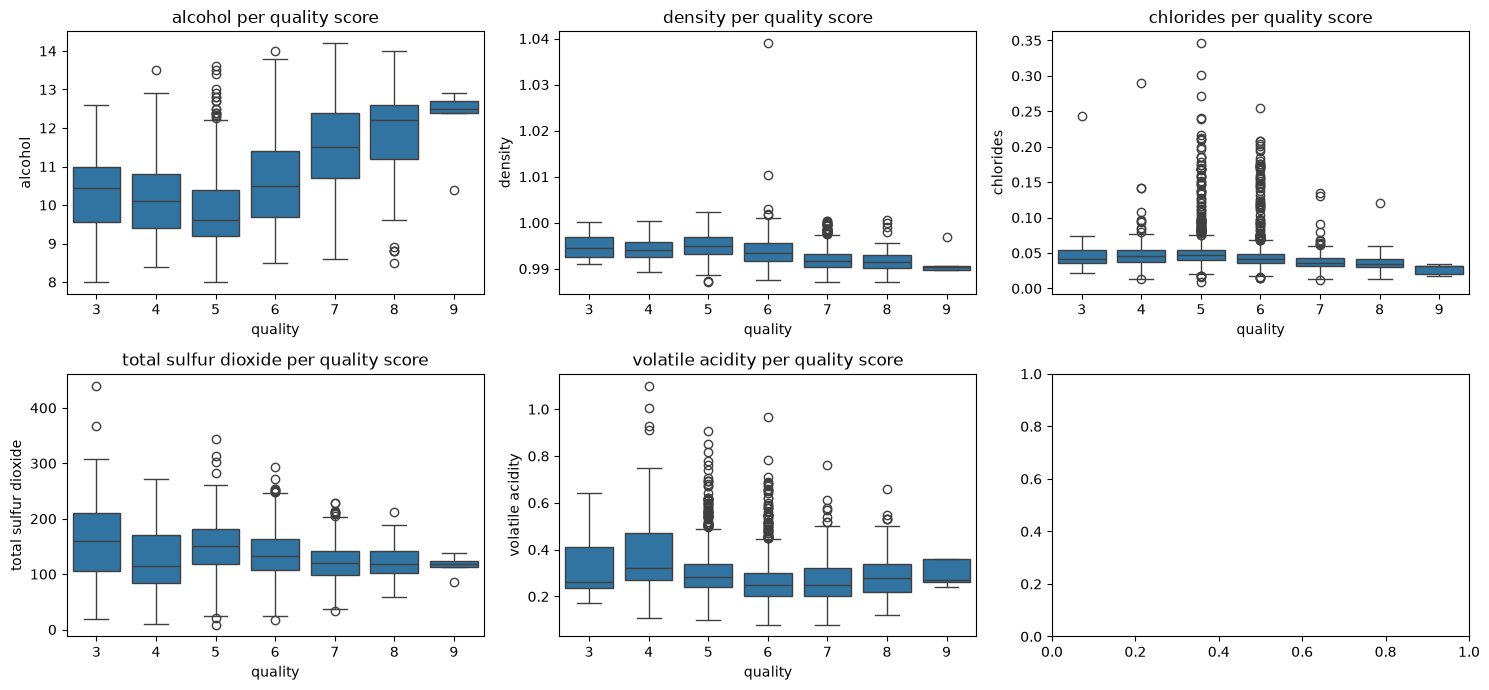

In [20]:
#the highest absolute correlation with quality
top = ['alcohol','density','chlorides','total sulfur dioxide','volatile acidity']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()
for ax,c in zip(axes, top):
    sns.boxplot(data=df, x='quality', y=c, ax=ax)
    ax.set_title(f'{c} per quality score')

plt.tight_layout()
plt.show()

### EDA Findings: Features vs Quality (White Wine)

Boxplot per  `quality`score for `sulphates`, `chlorides`, and`total sulfur dioxide`.

#### 1. Alcohol 
- Median rises concistently from score 5 to 9 (up to ~12.5).
- **(positive)** relationship and the clearest separation.
- Matches the direction of its correlation with `quality`.

#### 2. Density
- Slightly lower in higher-quality wines (7-8), consistent with higher alcohol lowering dnsity.
- **Weak negative** relationship: differences between scores are small.
- Many outlier at scores 7 and 8 (natural extreme value, retained).

#### 3. Chlorides
- lower and narrower in higher-quality wines, but median are similar across most classes.
- 
#### 4. Alcohol 

- Median roughly flat (-10) for scores 3-5, then rises sharply at scores 6-8 (up to ~12.5)
- Positive relathionship overall, but strongest at high quality levels.
- Best separator between mid (5) and high (7-8) quality wines.

#### 5. Volatile acidity

- Median decreases steadily from score 3 (~.0.85) to score 7-8 (~0.4).
- Clear **negative** relationship consistent with its chemical effect (vinegar-like-taste).
- Among the strongest discriminators, especially between low (3-4) and high (7-8) quality.

#### General Notes
- Boxes **overlap heavily** across scores, so each feature only a weak-moderate discriminator on its own.
- Score 3 and 8 have very few abservations, so their median are unstable. Interpretation focus on score 4-7.
- Outlier were **not removed** since they are chemically valid values rather than data-entry errors.
  
#### Implication for Next Step
- Highly skewed features (`chlorides`, `total sulfur dioxide`) are candidates for `log1p` if using scale sensitive models.
- Use a tree-based model as a baseline to capture non-linear relathionships.

### 2.4 Target Distribution

In [21]:
df['quality'].value_counts().sort_index()

quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64

# 3. Task Definition

In [22]:
X = df.drop('quality', axis=1)
y = (df['quality'] >= 6).astype(int)

print(y.value_counts())
print(y.value_counts(normalize=True).round(3))
#split it into binary classification but still imbalanced, so we need oversample

quality
1    2613
0    1348
Name: count, dtype: int64
quality
1    0.66
0    0.34
Name: proportion, dtype: float64


#### Target Definition / Classification Target
The original `quality` score (3-8) is converted into a binary label because its contain verry few observation. In multiclass method, these classes would be split even further across the train and validation folds, leaving the model with too few example to learn their patterns. Therefore the problem was reformulated as binary classification, where wine with quality >= 6 are labeled `good` (1) and the rest `not good` (0). This procedures more balanced target and more reliable evalutation metrics:
- `good = 1` if `quality >= 6`
- `not good = 0` otherwise

# 4. Train/Test/Split

In [23]:
df_shuffled = df.sample(frac=1, random_state=42)
n = len(df_shuffled)
train= df_shuffled.iloc[:int(0.6*(len(df_shuffled)))]
valid = df_shuffled.iloc[:int(0.6*(len(df_shuffled))):int(0.8*(len(df_shuffled)))]
test = df_shuffled.iloc[int(0.8*(len(df_shuffled))):]

In [24]:
X = df.drop('quality', axis=1)
y = (df['quality'] >= 6).astype(int)

In [25]:
#60% train, 40% for the rest (valid and test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

#the rest devided vy 2 ( valid and test)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [36]:
print(X_train.shape, y_train.shape)
print(X_valid.shape, y_valid.shape)
print(X_test.shape, y_test.shape)

(2376, 11) (2376,)
(792, 11) (792,)
(793, 11) (793,)


**Feature Engineering.** No new features were creared. In a previous project (Red Wine Classification and Regression). Engineered features added almost no improvement. The wine features are already numeric and chemically meaningful, and tree-based models can capture non-linear relationship and interaction on their own. Feature engineering may be explored in future work.

### 4.1 Preprocessing

#### 4.1.1. Scaling

In [29]:
scaler = StandardScaler()
X_train_scaling = scaler.fit_transform(X_train)
X_valid_scaling = scaler.transform(X_valid)
X_test_scaling = scaler.transform(X_test)

# 5. Modeling

### 5.1. Baseline : Dummy

In [35]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

pred = dummy.predict(X_valid)
print(accuracy_score(y_valid, pred))

0.6603535353535354


### 5.2. Baseline : Logistic Regression

In [38]:
lr = LogisticRegression(max_iter = 1000)
lr.fit(X_train_scaling, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

# 6. Evaluation

### 6.1 Validation Comparison

In [42]:
#logistic_rergretion_valid
pred_lr = lr.predict(X_valid_scaling)
print(accuracy_score(y_valid, pred_lr))
print(classification_report(y_valid, pred_lr))

0.7588383838383839
              precision    recall  f1-score   support

           0       0.69      0.54      0.60       269
           1       0.79      0.87      0.83       523

    accuracy                           0.76       792
   macro avg       0.74      0.70      0.71       792
weighted avg       0.75      0.76      0.75       792



**Findings**
- **Data contains signal** Logistic Regression (accuracy = 0.759) clearly outperforms the Dummy baseline (accuracy = 0.660). So the psycochemical features help predict wine quality.
- **Accuracy alone is not enough**. The `good`class makes up about 66% of the data, so Dummy already reasches 0.660 without learning anything.
- **The `not good` class is harder to predict.** For logistic regression, recall for class 0 is only 0.54 (F1 = 0.60), while class 1 reaches recall 0.87 (F1 = 0.83). The model tends to predict `good`
- **Benchmark for the next models:** accuracy 0.759 and class 0 F1 =0.60. Morer complex models should beat these numbers, especially by imporving class 0 recall.

In [53]:
#Randomforest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

rf2 = RandomForestClassifier(max_depth=10, min_samples_leaf=5, random_state=42)
rf2.fit(X_train, y_train)
pred_rf2 = rf2.predict(X_valid)
print(accuracy_score(y_valid, pred_rf2))
print(classification_report(y_valid, pred_rf2))

0.7815656565656566
              precision    recall  f1-score   support

           0       0.70      0.62      0.66       269
           1       0.82      0.86      0.84       523

    accuracy                           0.78       792
   macro avg       0.76      0.74      0.75       792
weighted avg       0.78      0.78      0.78       792



In [54]:
#KNN

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaling, y_train)

pred_knn =knn.predict(X_valid_scaling)
print(accuracy_score(y_valid, pred_knn))
print(classification_report(y_valid, pred_knn))

0.7550505050505051
              precision    recall  f1-score   support

           0       0.67      0.55      0.60       269
           1       0.79      0.86      0.82       523

    accuracy                           0.76       792
   macro avg       0.73      0.71      0.71       792
weighted avg       0.75      0.76      0.75       792



In [67]:
#comparing the model result
preds = {
    'Dummy' : dummy.predict(X_valid),
    "Logistic Regression" : pred_lr,
    'KNN' : pred_knn,
    'Random Forest' : pred_rf
}

rows = []
for name, p in preds.items():
    rows.append({
        'Model' : name,
        "Accuracy" : accuracy_score(y_valid, p),
        'Presicion (0)' : precision_score(y_valid, p, pos_label=0, zero_division=0),
        'Recall (0)' : recall_score(y_valid,p, pos_label=0),
        'F1 (0)' : f1_score(y_valid, p, pos_label=0),
        'F1 (1)' : f1_score(y_valid, p, pos_label=1),
    })

pd.DataFrame(rows).set_index('Model').round(3)

,Accuracy,Presicion (0),Recall (0),F1 (0),F1 (1)
Model,,,,,
Dummy,0.660,0.000,0.000,0.000,0.795
Logistic Regression,0.759,0.686,0.535,0.601,0.827
KNN,0.755,0.670,0.550,0.604,0.823
Random Forest,0.777,0.684,0.636,0.659,0.834


### 6.2. Overfitting check

In [57]:
#comparing the model result untuk cek overfitting jd sekarang pk data train
train_ov = {
    'Dummy' : dummy.predict(X_train),
    "Logistic Regression" : lr.predict(X_train_scaling),
    'KNN' : knn.predict(X_train_scaling),
    'Random Forest' : rf2.predict(X_train)
}

rows = []
for name, p in train_ov.items():
    rows.append({
        'Model' : name,
        "Accuracy" : accuracy_score(y_train, p),
        'Presicion (0)' : precision_score(y_train, p, pos_label=0, zero_division=0),
        'Recall (0)' : recall_score(y_train,p, pos_label=0),
        'F1 (0)' : f1_score(y_train, p, pos_label=0),
        'F1 (1)' : f1_score(y_train, p, pos_label=1),
    })

pd.DataFrame(rows).set_index('Model').round(3)

,Accuracy,Presicion (0),Recall (0),F1 (0),F1 (1)
Model,,,,,
Dummy,0.660,0.000,0.000,0.000,0.795
Logistic Regression,0.750,0.669,0.523,0.587,0.820
KNN,0.821,0.765,0.684,0.722,0.868
Random Forest,0.887,0.875,0.780,0.825,0.917


### 6.3. Final Test

In [58]:
pred_test = rf2.predict(X_test)
print(accuracy_score(y_test, pred_test))
print(classification_report(y_test, pred_test))

0.7591424968474149
              precision    recall  f1-score   support

           0       0.67      0.59      0.62       270
           1       0.80      0.85      0.82       523

    accuracy                           0.76       793
   macro avg       0.73      0.72      0.72       793
weighted avg       0.75      0.76      0.76       793



### 6.4. Confusion Matrix

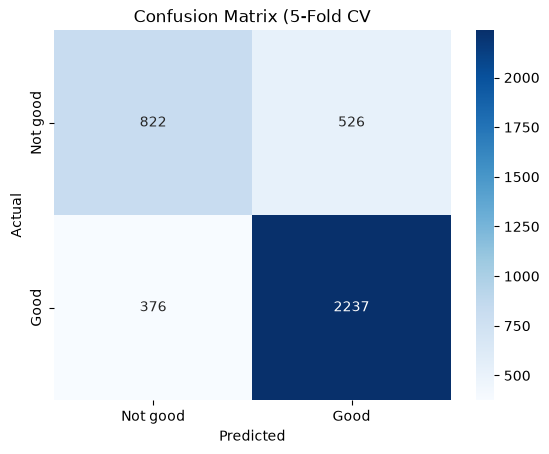

In [68]:
#confusion matrix
X = df.drop('quality', axis=1)
y_clf = (df['quality'] >= 6).astype(int)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
pred = cross_val_predict(RandomForestClassifier(random_state=42), X, y_clf, cv=cv)

cm = confusion_matrix(y_clf, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not good','Good'], yticklabels=['Not good','Good'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix (5-Fold CV")
plt.show()

**Findings**
- **The data contains signal.** All models clearly beat the dummy baseline (accuracy 0.660). Logistic regression reached 0.759 and KNN 0.775 on validation.
- **Random Forest performed** best on validation (accuracy 0.777, class 0 F1 0.659), mainly by improving recall for the `not good` class (0.636 vs 0.535 for Logistic Regression and 0.550 for KNN).
- **Overfitting was observed and reduced.** Default Random Forest scored 1.000 on train vs 0.777 on validation. Limiting depth (max_depth=10, min_samples_leaf=5) reduced the train_validation gp from 0.223 to 0.110 without lowering validaion accuracy.
- **Final test  performance:** accuracy 0.759, class 0 F1 0.62, class 1 F1 0.82. This is slightly below validation, which is expected on unseen data.
- **The `not good`** class remains harder to predict. Recall is 0.59 on test, so roughly 4 in 10 not-good wines are classified as good wines are classified as good. This is partly due to class imbalance (about 66% good) and strong feature overlap between classes.

**Limitations**
- The targetis defined by treshold quality $ \geq $ 6, so result depend on that choice.
- Quality scores are subjective sensory ratings, which limits hiw predictable they are from chemistry alone.
- The test set has about 270 `not good` samples, so metrics for that class carry some  uncertainty.
- Only one train/validation/test split was used.